# 01 – EDA: mức độ nghiêm trọng của tai nạn giao thông (STATS19 2021–2025)

Notebook này mô tả dữ liệu, kiểm tra mức độ thiếu dữ liệu và xem tỷ lệ KSI theo từng yếu tố (kèm khoảng tin cậy 95%), làm cơ sở chọn biến cho các mô hình ở bước sau.

KSI (Killed or Seriously Injured) là chỉ số chính DfT dùng để đo mức độ nghiêm trọng: một vụ được tính là KSI nếu có ít nhất một người tử vong (trong vòng 30 ngày) hoặc bị thương nặng (phải nằm viện, gãy xương, chấn động não, chấn thương nội tạng…).

## Câu hỏi nghiên cứu

| Ký hiệu | Câu hỏi | Mục liên quan trong notebook |
|---|---|---|
| RQ1 | Các yếu tố đường xá (giới hạn tốc độ, loại đường, giao lộ, thành thị hay nông thôn) liên quan thế nào đến khả năng một vụ tai nạn là KSI? | Mục 4 |
| RQ2 | Thời tiết, điều kiện ánh sáng và mặt đường liên quan thế nào đến mức độ nghiêm trọng, và có tương tác với các yếu tố đường xá không? | Mục 5 |
| RQ3 | Khi xét đồng thời các yếu tố (gồm cả phương tiện và con người), yếu tố nào quan trọng nhất? | Mục 6, 7, 8 |
| RQ4 | Việc Wales hạ giới hạn tốc độ mặc định ở khu dân cư từ 30 xuống 20 mph (từ ngày 17/9/2023) có làm thay đổi mức độ nghiêm trọng của tai nạn so với England không? | Mục 3, 9 |

Notebook này chỉ dừng ở mức mô tả từng yếu tố riêng lẻ. RQ1 và RQ2 được trả lời bằng hồi quy logistic, RQ3 bằng mô hình học máy (XGBoost) kết hợp SHAP, RQ4 bằng phương pháp difference-in-differences, trong các notebook tiếp theo.

## Quy ước chung

- Dữ liệu: STATS19 (DfT), 2021–2025, Great Britain (England, Wales, Scotland).
- Biến mục tiêu: `ksi_adj`, tức KSI đã điều chỉnh theo phương pháp của DfT. Với vụ được ghi theo hệ thống dựa trên loại chấn thương (CRASH), giá trị là 0 hoặc 1; với vụ ghi theo hệ thống cũ, giá trị là xác suất vụ đó là KSI do DfT ước tính; vụ tử vong luôn bằng 1. Tỷ lệ KSI của một nhóm là trung bình `ksi_adj`.
- Đơn vị phân tích: vụ tai nạn (`collision_analysis`), riêng mục 8 là người bị thương (`casualty_analysis`).
- Khoảng tin cậy 95% theo phương pháp Wilson. Vì `ksi_adj` có giá trị lẻ, tổng `ksi_adj` được coi là số vụ KSI; đây là xấp xỉ, sai số không đáng kể khi cỡ mẫu lớn.
- Nhóm có dưới 30 vụ hoặc dưới 5 vụ KSI được đánh dấu (vẽ sọc mờ) và không diễn giải.
- Giới hạn: dữ liệu chỉ gồm các vụ có người bị thương được cảnh sát ghi nhận, nên kết quả phản ánh mức độ nghiêm trọng khi tai nạn đã xảy ra, không phải nguy cơ xảy ra tai nạn. Các khác biệt trong notebook là tương quan, chưa kiểm soát các yếu tố khác.

Cách đọc biểu đồ cột: mỗi thanh là tỷ lệ KSI của một nhóm, con số bên cạnh là tỷ lệ và số vụ (n). Vạch đen ở đầu thanh là khoảng tin cậy 95%: nếu vạch của hai nhóm không chồng lên nhau, khác biệt giữa hai nhóm khó có thể do ngẫu nhiên. Đường đứt nét dọc là tỷ lệ KSI chung của toàn bộ dữ liệu (25,3%). Nhãn các nhóm được giữ nguyên tiếng Anh theo Data Guide của DfT; nghĩa tiếng Việt được ghi trong chú thích dưới mỗi hình.

Để chạy lại: chạy pipeline `python -m src.etl.build` trước, sau đó chạy notebook từ trên xuống.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analysis import plots
from src.analysis.metrics import ksi_rate_table, missing_table
from src.config import POLICY_DATE, PROCESSED_DIR, REPORTS_DIR

FIG = REPORTS_DIR / "figures"
TAB = REPORTS_DIR / "eda"
TAB.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 160)
plt.rcParams["figure.max_open_warning"] = 0

col = pd.read_parquet(PROCESSED_DIR / "collision_analysis.parquet")
cas = pd.read_parquet(PROCESSED_DIR / "casualty_analysis.parquet")
col["speed_limit"] = col["speed_limit"].astype("Int64")  # 20, 30 ... instead of 20.0
OVERALL = col["ksi_adj"].mean()
print(f"collisions: {len(col):,}   casualties: {len(cas):,}   overall KSI (adjusted): {OVERALL:.2%}")

collisions: 513,801   casualties: 652,821   overall KSI (adjusted): 25.29%


In [2]:
def show(by, title, fname, df=None, unit="vụ", filters="không", sort=False, rename=None):
    """KSI rate table + bar chart; saves CSV to reports/eda and PNG to reports/figures."""
    d = col if df is None else df
    t = ksi_rate_table(d, by)
    if sort:
        t = t.sort_values("rate", ascending=False)
    if rename:
        t.index = [rename.get(i, i) for i in t.index]
    t.to_csv(TAB / f"{fname}.csv")
    note = plots.data_note(int(t["n"].sum()), unit=unit, filters=filters)
    plots.rate_bars(t, title, note, overall=d["ksi_adj"].mean(), path=FIG / f"{fname}.png")
    plt.show()
    return t.style.format({"rate": "{:.1%}", "ci_low": "{:.1%}", "ci_high": "{:.1%}",
                           "rate_raw": "{:.1%}", "ksi": "{:,.0f}", "n": "{:,}"})


def rate_pivot(d, rows, cols):
    """Pivot of KSI rate (small groups masked) and of counts."""
    t = ksi_rate_table(d, [rows, cols])
    return t["rate"].where(~t["small_n"]).unstack(cols), t["n"].unstack(cols)

Ý nghĩa các cột trong bảng kết quả: `n` là số vụ của nhóm; `ksi` là số vụ KSI (đã điều chỉnh); `rate` là tỷ lệ KSI; `ci_low`, `ci_high` là cận dưới và cận trên của khoảng tin cậy 95%; `rate_raw` là tỷ lệ KSI tính theo mức độ cảnh sát ghi nhận (chưa điều chỉnh); `small_n` cho biết nhóm có quá ít dữ liệu hay không.

## 1. Mô tả dữ liệu

Hai bảng phân tích được tạo bởi `src/etl/build.py`: một bảng ở mức vụ và một bảng ở mức người. Số vụ, số vụ tử vong, số vụ KSI (gốc và đã điều chỉnh) theo từng năm khớp hoàn toàn với bảng RAS0101 do DfT công bố.

In [3]:
by_year = col.groupby("collision_year").agg(
    collisions=("collision_index", "size"),
    casualties=("number_of_casualties", "sum"),
    vehicles=("number_of_vehicles", "sum"),
    ksi_rate_raw=("ksi_raw", "mean"),
    ksi_rate_adj=("ksi_adj", "mean"),
)
by_year.loc["Tổng"] = [by_year.collisions.sum(), by_year.casualties.sum(), by_year.vehicles.sum(),
                       col.ksi_raw.mean(), col.ksi_adj.mean()]
by_year.to_csv(TAB / "01_by_year.csv")
by_year.style.format({"collisions": "{:,.0f}", "casualties": "{:,.0f}", "vehicles": "{:,.0f}",
                      "ksi_rate_raw": "{:.1%}", "ksi_rate_adj": "{:.1%}"})

,collisions,casualties,vehicles,ksi_rate_raw,ksi_rate_adj
collision_year,,,,,
2021,"101,087","128,209","186,443",22.5%,23.9%
2022,"106,004","135,480","193,545",23.5%,24.7%
2023,"104,258","132,977","189,815",23.9%,25.1%
2024,"100,927","128,272","183,514",24.8%,26.0%
2025,"101,525","127,883","183,948",26.2%,26.8%
Tổng,"513,801","652,821","937,265",24.2%,25.3%


Bảng 1.1: mỗi năm có khoảng 101–106 nghìn vụ tai nạn có người bị thương, với khoảng 128–135 nghìn người bị thương và 184–194 nghìn phương tiện liên quan. Cột `ksi_rate_raw` là tỷ lệ KSI theo ghi nhận của cảnh sát, `ksi_rate_adj` là tỷ lệ đã điều chỉnh. Trong cả giai đoạn, khoảng một phần tư số vụ (25,3%) có ít nhất một người tử vong hoặc bị thương nặng.

In [4]:
col.groupby("country", observed=True).agg(collisions=("collision_index", "size"),
                                          ksi_rate_adj=("ksi_adj", "mean")).style.format(
    {"collisions": "{:,}", "ksi_rate_adj": "{:.1%}"})

,collisions,ksi_rate_adj
country,,
England,"477,484",24.2%
Wales,"15,787",35.9%
Scotland,"20,530",42.5%


Bảng 1.2: England chiếm khoảng 93% số vụ; Wales (15.787 vụ, khoảng 3%) và Scotland (20.530 vụ) chiếm phần nhỏ. Quy mô nhỏ của Wales là một giới hạn cần lưu ý khi đánh giá chính sách 20 mph (RQ4).

### Danh sách biến

Bảng dưới liệt kê các biến của bảng mức vụ: kiểu dữ liệu, tỷ lệ thiếu, số giá trị khác nhau và một vài giá trị ví dụ. Bảng đầy đủ cho cả hai mức được lưu ở `reports/eda/01_variable_list_collision.csv` và `reports/eda/01_variable_list_casualty.csv`.

In [5]:
def variable_list(df):
    rows = []
    for c in df.columns:
        s = df[c]
        if s.dtype.name in ("category", "string", "object", "boolean", "bool"):
            ex = "; ".join(s.dropna().astype(str).value_counts().index[:3])
        else:
            ex = f"{s.min()} – {s.max()}"
        rows.append({"column": c, "dtype": str(s.dtype), "missing_share": round(s.isna().mean(), 4),
                     "n_unique": s.nunique(), "examples": ex})
    return pd.DataFrame(rows)

vl_col, vl_cas = variable_list(col), variable_list(cas)
vl_col.to_csv(TAB / "01_variable_list_collision.csv", index=False)
vl_cas.to_csv(TAB / "01_variable_list_casualty.csv", index=False)
print(len(vl_col), "collision-level columns;", len(vl_cas), "casualty-level columns")
vl_col

66 collision-level columns; 42 casualty-level columns


,column,dtype,missing_share,n_unique,examples
0,collision_index,string,0.0000,513801,202417H105824; 202517M115025; 202517L306225
1,collision_year,Int64,0.0000,5,2021 – 2025
2,collision_ref_no,string,0.0000,510837,340NN2472; 340NN3412; 340NN3492
3,location_easting_osgr,float64,0.0001,245276,67564.0 – 655345.0
4,location_northing_osgr,float64,0.0001,263601,10211.0 – 1179892.0
5,longitude,float64,0.0001,437862,-7.486852 – 1.759829
6,latitude,float64,0.0001,412450,49.91221 – 60.500008
7,police_force,category,0.0000,44,Metropolitan Police; West Midlands; Police Sco...
8,collision_severity,category,0.0000,3,Slight; Serious; Fatal
9,number_of_vehicles,int64,0.0000,19,1 – 26


## 2. Dữ liệu thiếu

Các mã mang nghĩa không có thông tin (-1, "unknown", "not known"…) đã được chuyển thành giá trị trống ở bước làm sạch. Cột thiếu nhiều sẽ không được dùng, hoặc được đưa vào mô hình với một nhóm "không rõ" riêng.

In [6]:
miss = missing_table(col)
miss.to_csv(TAB / "02_missing_collision.csv")
miss[miss.missing_share > 0].style.format({"missing_share": "{:.1%}", "n_missing": "{:,}"})

,missing_share,n_missing
enhanced_severity_collision,39.9%,"204,752"
second_road_number,34.7%,"178,098"
special_conditions_at_site,31.5%,"161,928"
trunk_road_flag,7.1%,"36,318"
max_driver_age,5.4%,"27,640"
min_driver_age,5.4%,"27,640"
pedestrian_crossing,4.6%,"23,890"
junction_detail,4.2%,"21,411"
carriageway_hazards,3.7%,"19,063"
junction_control,2.9%,"14,826"


Bảng 2.1 (mức vụ): phần lớn các biến chính về đường xá và môi trường thiếu dưới 5% (thời tiết 2,8%, loại đường 2,5%, ánh sáng dưới 0,1%). Các biến thiếu nhiều là `enhanced_severity_collision` (40%, chỉ một số lực lượng cảnh sát ghi), `second_road_number` (35%) và `special_conditions_at_site` (31,5%, bị thay thế trong đặc tả dữ liệu năm 2024). Tuổi tài xế thiếu ở 5,4% số vụ.

In [7]:
miss_cas = missing_table(cas)
miss_cas.to_csv(TAB / "02_missing_casualty.csv")
miss_cas[miss_cas.missing_share > 0.01].style.format({"missing_share": "{:.1%}", "n_missing": "{:,}"})

,missing_share,n_missing
casualty_distance_banding,65.7%,"428,604"
enhanced_casualty_severity,34.7%,"226,536"
casualty_imd_decile,11.2%,"73,236"
pedestrian_road_maintenance_worker,5.5%,"35,977"
pedestrian_movement,4.2%,"27,282"
junction_detail,3.8%,"24,564"
weather_conditions,2.4%,"15,908"
road_type,2.2%,"14,178"
age_of_casualty,2.2%,"14,106"
age_band_of_casualty,2.2%,"14,106"


Bảng 2.2 (mức người, chỉ liệt kê biến thiếu trên 1%): khoảng cách từ nhà nạn nhân đến nơi xảy ra tai nạn thiếu 66% nên không dùng được; chỉ số thiếu thốn khu vực (IMD) thiếu 11%; tuổi nạn nhân chỉ thiếu khoảng 2%.

## 3. Xu hướng KSI và thay đổi cách ghi nhận mức độ thương tích

Cảnh sát Anh dùng hai cách ghi mức độ thương tích. Theo cách cũ, cảnh sát tự đánh giá người bị thương nặng hay nhẹ. Theo cách mới (hệ thống CRASH), cảnh sát chọn loại chấn thương cụ thể và hệ thống tự xếp mức độ; cách này ghi nhận được nhiều ca nặng hơn. Các lực lượng cảnh sát chuyển sang cách mới vào những thời điểm khác nhau, làm tỷ lệ KSI gốc tăng mà không phản ánh thay đổi thực tế. KSI đã điều chỉnh loại bỏ phần lớn ảnh hưởng này, nên được dùng làm biến mục tiêu chính.

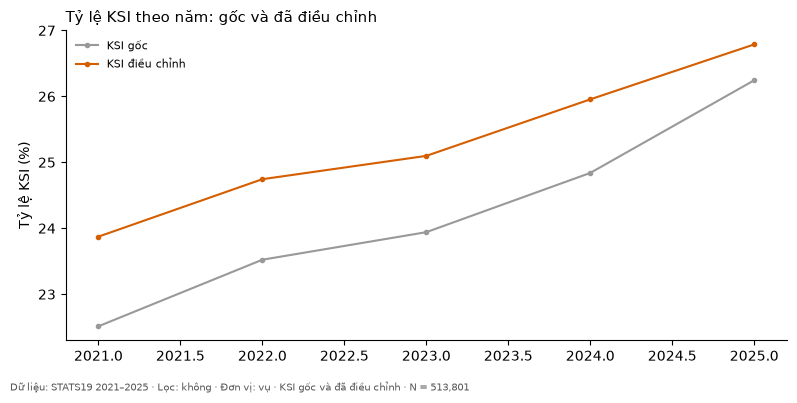

,KSI gốc,KSI điều chỉnh
collision_year,,
2021,22.5%,23.9%
2022,23.5%,24.7%
2023,23.9%,25.1%
2024,24.8%,26.0%
2025,26.2%,26.8%


In [8]:
yr = col.groupby("collision_year")[["ksi_raw", "ksi_adj"]].mean()
yr.columns = ["KSI gốc", "KSI điều chỉnh"]
plots.lines(yr, "Tỷ lệ KSI theo năm: gốc và đã điều chỉnh",
            plots.data_note(len(col), severity="KSI gốc và đã điều chỉnh"), ylabel="Tỷ lệ KSI (%)",
            colors={"KSI gốc": plots.RAW_COLOR, "KSI điều chỉnh": plots.KSI_COLOR},
            path=FIG / "03_ksi_by_year.png")
plt.show()
yr.style.format("{:.1%}")

Hình 3.1: đường xám là tỷ lệ KSI theo ghi nhận của cảnh sát, đường cam là tỷ lệ đã điều chỉnh. Tỷ lệ gốc tăng từ 22,5% (2021) lên 26,2% (2025), còn tỷ lệ điều chỉnh tăng ít hơn, từ 23,9% lên 26,8%. Khoảng cách giữa hai đường thu hẹp dần vì ngày càng ít vụ còn được ghi theo cách cũ, nên phần cần điều chỉnh nhỏ đi.

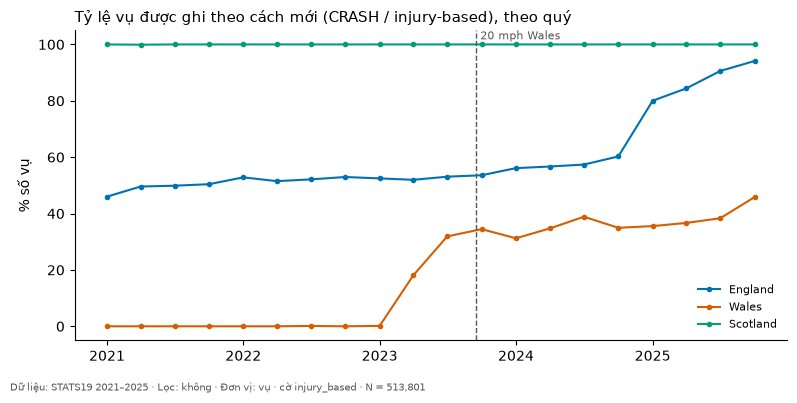

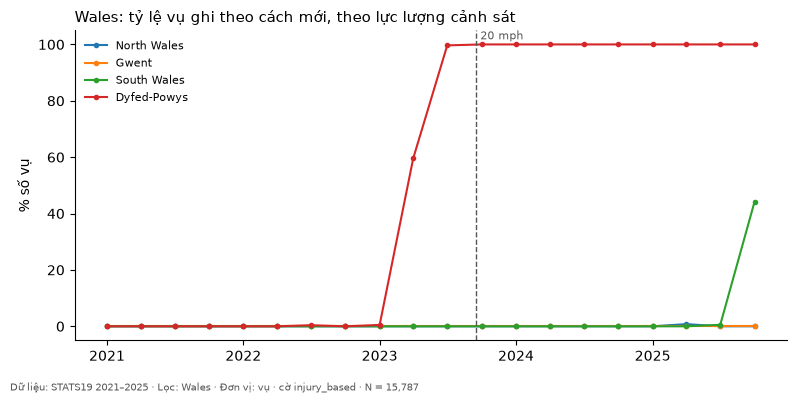

In [9]:
col["quarter"] = col["date"].dt.to_period("Q").dt.start_time
ib = col.groupby(["quarter", "country"], observed=True)["collision_injury_based"].mean().unstack()
plots.lines(ib, "Tỷ lệ vụ được ghi theo cách mới (CRASH / injury-based), theo quý",
            plots.data_note(len(col), severity="cờ injury_based"), ylabel="% số vụ",
            colors=plots.SERIES_COLORS, vline=(pd.Timestamp(POLICY_DATE), "20 mph Wales"),
            path=FIG / "03_injury_based_by_country.png")
plt.show()

wales = col[col.country == "Wales"]
ibw = wales.groupby(["quarter", "police_force"], observed=True)["collision_injury_based"].mean().unstack()
plots.lines(ibw, "Wales: tỷ lệ vụ ghi theo cách mới, theo lực lượng cảnh sát",
            plots.data_note(len(wales), filters="Wales", severity="cờ injury_based"), ylabel="% số vụ",
            vline=(pd.Timestamp(POLICY_DATE), "20 mph"), path=FIG / "03_injury_based_wales_forces.png")
plt.show()

Hình 3.2: Scotland dùng cách ghi mới cho toàn bộ các vụ trong cả giai đoạn. Ở England, tỷ lệ này tăng từ khoảng 49% (2021) lên 87% (2025). Wales gần như chưa dùng trước năm 2023 và đạt 39% vào năm 2025.

Hình 3.3: trong bốn lực lượng cảnh sát ở Wales, Dyfed-Powys chuyển sang cách ghi mới trong năm 2023 (34% số vụ ở nửa đầu năm, 100% từ nửa cuối năm), trùng với thời điểm áp dụng chính sách 20 mph. South Wales bắt đầu chuyển từ cuối năm 2025, còn North Wales và Gwent chưa chuyển. Nếu dùng KSI gốc, sự thay đổi cách ghi này có thể bị nhầm thành tác động của chính sách; đây là lý do RQ4 dùng KSI đã điều chỉnh và có kiểm tra thêm khi loại Dyfed-Powys.

## 4. Yếu tố đường xá (RQ1)

Câu hỏi: giới hạn tốc độ, loại đường, giao lộ và khu vực thành thị hay nông thôn liên quan thế nào đến khả năng một vụ tai nạn là KSI?

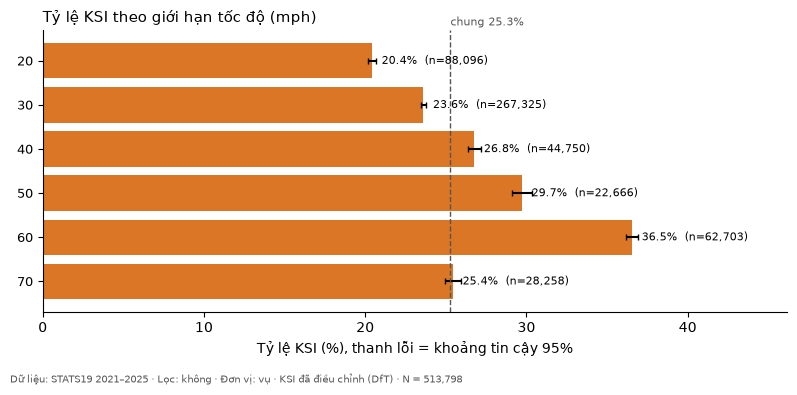

,n,ksi,rate,ci_low,ci_high,rate_raw,small_n
speed_limit,,,,,,,
20,"88,096","17,991",20.4%,20.2%,20.7%,19.7%,False
30,"267,325","63,104",23.6%,23.4%,23.8%,22.6%,False
40,"44,750","11,978",26.8%,26.4%,27.2%,25.7%,False
50,"22,666","6,738",29.7%,29.1%,30.3%,28.3%,False
60,"62,703","22,918",36.5%,36.2%,36.9%,34.5%,False
70,"28,258","7,190",25.4%,24.9%,26.0%,24.6%,False


In [10]:
show("speed_limit", "Tỷ lệ KSI theo giới hạn tốc độ (mph)", "04_speed_limit")

Hình 4.1: mỗi thanh là tỷ lệ KSI của các vụ xảy ra trên đường có giới hạn tốc độ tương ứng (1 mph ≈ 1,6 km/h). Tỷ lệ tăng đều từ 20,4% ở đường 20 mph lên 36,5% ở đường 60 mph. Đường 70 mph, chủ yếu là đường cao tốc và đường đôi có dải phân cách, có tỷ lệ thấp hơn (25,4%), có thể vì loại đường này ít va chạm trực diện và không có người đi bộ.

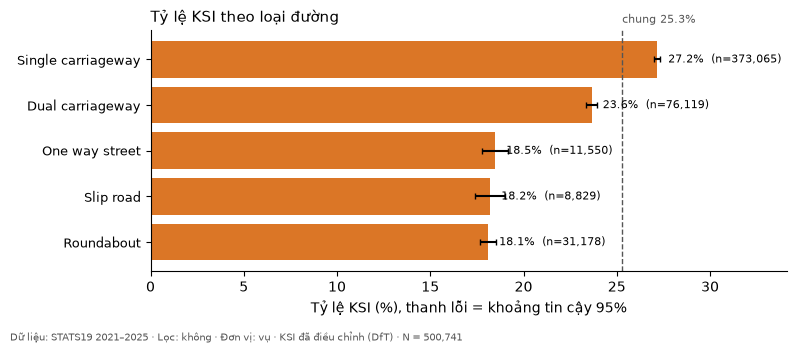

,n,ksi,rate,ci_low,ci_high,rate_raw,small_n
road_type,,,,,,,
Single carriageway,"373,065","101,313",27.2%,27.0%,27.3%,25.9%,False
Dual carriageway,"76,119","18,000",23.6%,23.3%,24.0%,22.9%,False
One way street,"11,550","2,134",18.5%,17.8%,19.2%,17.7%,False
Slip road,"8,829","1,608",18.2%,17.4%,19.0%,17.9%,False
Roundabout,"31,178","5,642",18.1%,17.7%,18.5%,17.2%,False


In [11]:
show("road_type", "Tỷ lệ KSI theo loại đường", "04_road_type", sort=True)

Hình 4.2: Single carriageway là đường hai chiều không có dải phân cách giữa; Dual carriageway là đường đôi có dải phân cách; One way street là đường một chiều; Slip road là đường nhánh ra vào đường lớn; Roundabout là vòng xuyến. Đường hai chiều không có dải phân cách có tỷ lệ cao nhất (27,2%) và chiếm phần lớn số vụ. Vòng xuyến, đường nhánh và đường một chiều thấp nhất (khoảng 18%), phù hợp với việc xe chạy chậm hơn và ít va chạm trực diện ở các loại đường này.

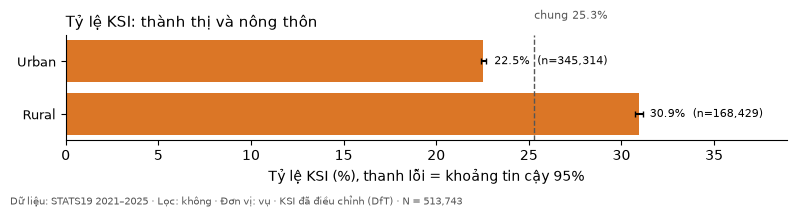

,n,ksi,rate,ci_low,ci_high,rate_raw,small_n
urban_or_rural_area,,,,,,,
Urban,"345,314","77,810",22.5%,22.4%,22.7%,21.7%,False
Rural,"168,429","52,088",30.9%,30.7%,31.1%,29.4%,False


In [12]:
show("urban_or_rural_area", "Tỷ lệ KSI: thành thị và nông thôn", "04_urban_rural")

Hình 4.3: Urban là thành thị, Rural là nông thôn. Vụ ở nông thôn có tỷ lệ KSI 30,9%, cao hơn thành thị (22,5%) khoảng 8 điểm phần trăm, dù số vụ ở nông thôn chỉ bằng khoảng một nửa thành thị.

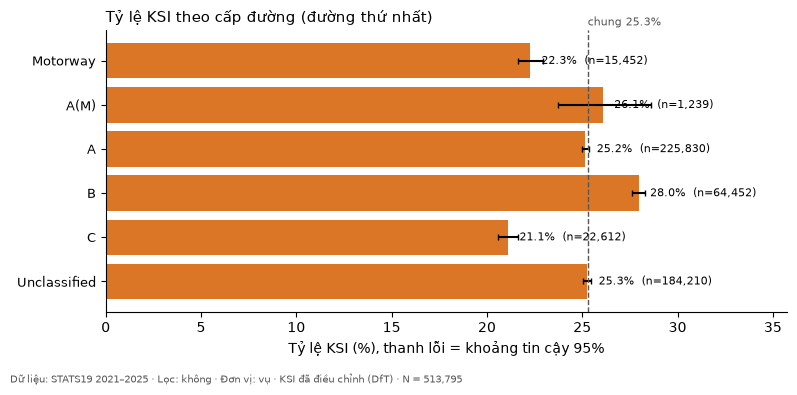

,n,ksi,rate,ci_low,ci_high,rate_raw,small_n
first_road_class,,,,,,,
Motorway,"15,452","3,439",22.3%,21.6%,22.9%,21.6%,False
A(M),"1,239",323,26.1%,23.7%,28.6%,25.4%,False
A,"225,830","56,827",25.2%,25.0%,25.3%,24.2%,False
B,"64,452","18,020",28.0%,27.6%,28.3%,26.7%,False
C,"22,612","4,773",21.1%,20.6%,21.6%,19.8%,False
Unclassified,"184,210","46,536",25.3%,25.1%,25.5%,24.2%,False


In [13]:
show("first_road_class", "Tỷ lệ KSI theo cấp đường (đường thứ nhất)", "04_road_class")

Hình 4.4: Motorway là đường cao tốc; A(M) là đoạn đường cấp A được nâng lên tiêu chuẩn cao tốc; A, B, C là các cấp đường từ chính đến phụ; Unclassified là đường không phân cấp (chủ yếu đường nội bộ, đường trong khu dân cư). Đường cấp B có tỷ lệ cao nhất (28,0%); đường cao tốc (22,3%) và đường cấp C (21,1%) thấp nhất.

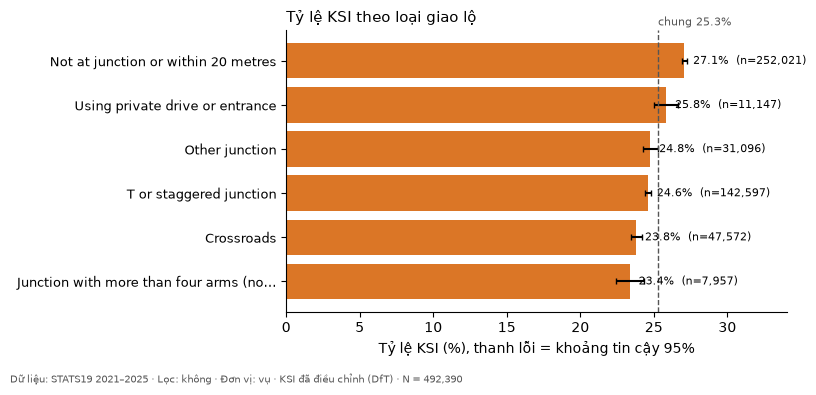

,n,ksi,rate,ci_low,ci_high,rate_raw,small_n
junction_detail,,,,,,,
Not at junction or within 20 metres,"252,021","68,228",27.1%,26.9%,27.2%,25.8%,False
Using private drive or entrance,"11,147","2,881",25.8%,25.0%,26.7%,24.3%,False
Other junction,"31,096","7,702",24.8%,24.3%,25.3%,24.3%,False
T or staggered junction,"142,597","35,091",24.6%,24.4%,24.8%,23.5%,False
Crossroads,"47,572","11,322",23.8%,23.4%,24.2%,22.8%,False
Junction with more than four arms (not roundabout),"7,957","1,859",23.4%,22.4%,24.3%,22.7%,False


In [14]:
show("junction_detail", "Tỷ lệ KSI theo loại giao lộ", "04_junction_detail", sort=True)

Hình 4.5: Not at junction là vụ không xảy ra ở giao lộ (cách giao lộ hơn 20 m); T or staggered junction là ngã ba hoặc giao lộ so le; Crossroads là ngã tư; Using private drive or entrance là lối ra vào nhà hoặc khu riêng; Junction with more than four arms là giao lộ có trên bốn nhánh. Vụ không ở giao lộ có tỷ lệ cao nhất (27,1%); các vụ ở giao lộ thấp hơn (23–26%), có thể vì xe phải giảm tốc khi đi qua giao lộ.

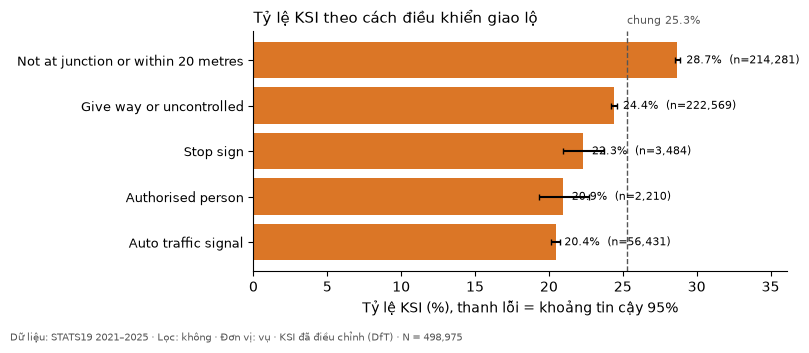

,n,ksi,rate,ci_low,ci_high,rate_raw,small_n
junction_control,,,,,,,
Not at junction or within 20 metres,"214,281","61,497",28.7%,28.5%,28.9%,27.5%,False
Give way or uncontrolled,"222,569","54,327",24.4%,24.2%,24.6%,23.3%,False
Stop sign,"3,484",777,22.3%,21.0%,23.7%,21.6%,False
Authorised person,"2,210",463,20.9%,19.3%,22.7%,20.6%,False
Auto traffic signal,"56,431","11,537",20.4%,20.1%,20.8%,19.6%,False


In [15]:
show("junction_control", "Tỷ lệ KSI theo cách điều khiển giao lộ", "04_junction_control", sort=True)

Hình 4.6: Give way or uncontrolled là giao lộ có biển nhường đường hoặc không có điều khiển; Auto traffic signal là đèn tín hiệu; Stop sign là biển dừng; Authorised person là người điều khiển giao thông. Trong các vụ ở giao lộ, giao lộ có đèn tín hiệu có tỷ lệ thấp nhất (20,4%), thấp hơn giao lộ nhường đường hoặc không điều khiển (24,4%).

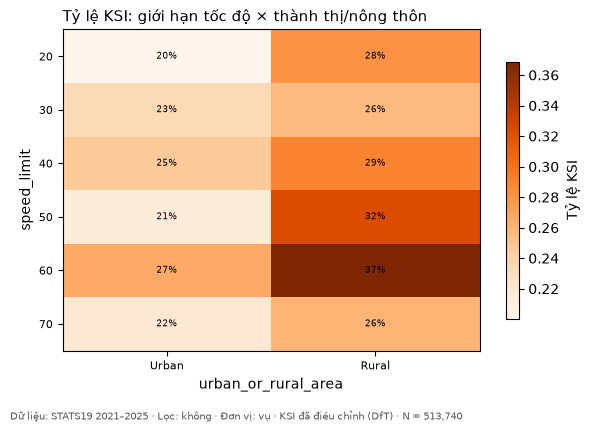

rate                 n       
urban_or_rural_area     Urban     Rural   Urban  Rural
speed_limit                                           
20                   0.200478  0.280788   84007   4080
30                   0.232553  0.256239  227810  39488
40                   0.245597  0.289884   22500  22245
50                   0.212570  0.323394    5341  17323
60                   0.265840  0.368787    2000  60693
70                   0.218054  0.259796    3653  24600

In [16]:
p, n = rate_pivot(col, "speed_limit", "urban_or_rural_area")
plots.heatmap(p, "Tỷ lệ KSI: giới hạn tốc độ × thành thị/nông thôn",
              plots.data_note(int(n.sum().sum())), path=FIG / "04_speed_x_urban.png")
plt.show()
pd.concat({"rate": p, "n": n}, axis=1)

Hình 4.7: mỗi ô là tỷ lệ KSI của các vụ có cùng giới hạn tốc độ (hàng) và khu vực (cột); màu càng đậm, tỷ lệ càng cao. Ở cùng một giới hạn tốc độ, vụ ở nông thôn luôn có tỷ lệ cao hơn thành thị, ví dụ 36,9% so với 26,6% ở đường 60 mph, và 32,3% so với 21,3% ở đường 50 mph. Như vậy, khác biệt giữa nông thôn và thành thị không chỉ do tốc độ cho phép. Hai biến này liên quan chặt với nhau (phần lớn đường 60 mph nằm ở nông thôn), nên mô hình cần kiểm tra đa cộng tuyến.

## 5. Thời tiết, ánh sáng, mặt đường (RQ2)

Câu hỏi: thời tiết, điều kiện ánh sáng và mặt đường liên quan thế nào đến mức độ nghiêm trọng, và mức độ liên quan đó có thay đổi theo yếu tố đường xá không?

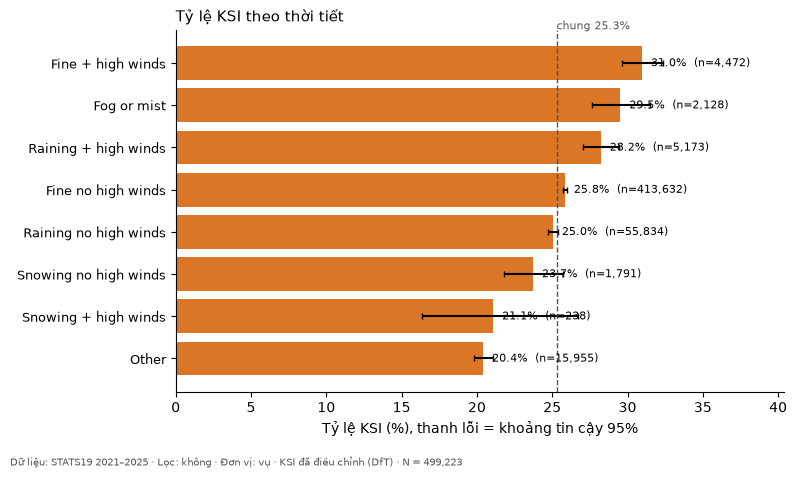

,n,ksi,rate,ci_low,ci_high,rate_raw,small_n
weather_conditions,,,,,,,
Fine + high winds,"4,472","1,384",31.0%,29.6%,32.3%,29.7%,False
Fog or mist,"2,128",628,29.5%,27.6%,31.5%,28.1%,False
Raining + high winds,"5,173","1,460",28.2%,27.0%,29.5%,26.8%,False
Fine no high winds,"413,632","106,889",25.8%,25.7%,26.0%,24.7%,False
Raining no high winds,"55,834","13,985",25.0%,24.7%,25.4%,24.0%,False
Snowing no high winds,"1,791",425,23.7%,21.8%,25.7%,22.7%,False
Snowing + high winds,238,50,21.1%,16.4%,26.7%,19.3%,False
Other,"15,955","3,257",20.4%,19.8%,21.0%,19.8%,False


In [17]:
show("weather_conditions", "Tỷ lệ KSI theo thời tiết", "05_weather", sort=True)

Hình 5.1: Fine no high winds là trời đẹp, không có gió mạnh; Raining là mưa; Snowing là tuyết rơi; "+ high winds" là kèm gió mạnh; Fog or mist là sương mù; Other là điều kiện khác. Khoảng 83% số vụ xảy ra khi trời đẹp. Khác biệt giữa các nhóm thời tiết nhỏ: trời mưa (25,0%) gần như bằng trời đẹp (25,8%). Các nhóm có gió mạnh hoặc sương mù cao hơn (28–31%) nhưng số vụ ít nên khoảng tin cậy rộng.

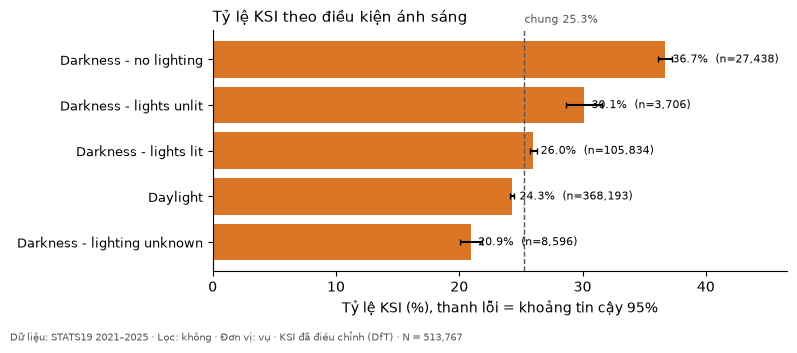

,n,ksi,rate,ci_low,ci_high,rate_raw,small_n
light_conditions,,,,,,,
Darkness - no lighting,"27,438","10,068",36.7%,36.1%,37.3%,34.9%,False
Darkness - lights unlit,"3,706","1,116",30.1%,28.7%,31.6%,29.1%,False
Darkness - lights lit,"105,834","27,520",26.0%,25.7%,26.3%,25.1%,False
Daylight,"368,193","89,402",24.3%,24.1%,24.4%,23.2%,False
Darkness - lighting unknown,"8,596","1,799",20.9%,20.1%,21.8%,19.9%,False


In [18]:
show("light_conditions", "Tỷ lệ KSI theo điều kiện ánh sáng", "05_light", sort=True)

Hình 5.2: Daylight là ban ngày; Darkness - lights lit là trời tối, đèn đường đang sáng; Darkness - lights unlit là có đèn đường nhưng không sáng; Darkness - no lighting là không có đèn đường; Darkness - lighting unknown là trời tối, không rõ tình trạng đèn. Vụ xảy ra khi trời tối và không có đèn đường có tỷ lệ cao nhất (36,7%), cao hơn ban ngày (24,3%) khoảng 12 điểm phần trăm. Khi trời tối nhưng có đèn đường sáng, tỷ lệ chỉ cao hơn ban ngày một chút (26,0%).

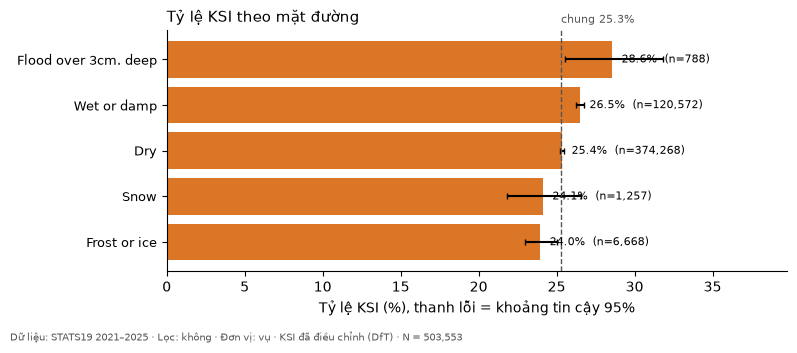

,n,ksi,rate,ci_low,ci_high,rate_raw,small_n
road_surface_conditions,,,,,,,
Flood over 3cm. deep,788,225,28.6%,25.5%,31.8%,27.3%,False
Wet or damp,"120,572","31,966",26.5%,26.3%,26.8%,25.4%,False
Dry,"374,268","94,931",25.4%,25.2%,25.5%,24.3%,False
Snow,"1,257",303,24.1%,21.8%,26.6%,23.0%,False
Frost or ice,"6,668","1,597",24.0%,22.9%,25.0%,22.6%,False


In [19]:
show("road_surface_conditions", "Tỷ lệ KSI theo mặt đường", "05_surface", sort=True)

Hình 5.3: Dry là mặt đường khô; Wet or damp là ướt hoặc ẩm; Frost or ice là sương giá hoặc đóng băng; Snow là có tuyết; Flood over 3cm deep là ngập nước trên 3 cm. Khác biệt giữa các nhóm nhỏ; mặt đường đóng băng hoặc có tuyết (khoảng 24%) thậm chí thấp hơn mặt đường khô (25,4%). Kết quả này giống với thời tiết ở hình 5.1.

### Quan sát ban đầu về tương tác

Tương tác xảy ra khi mức độ liên quan của một yếu tố thay đổi tùy theo một yếu tố khác, ví dụ trời tối có thể gắn với mức độ nghiêm trọng cao hơn ở nông thôn nhiều hơn so với ở thành thị. Phần này chỉ quan sát trên bảng chéo; kiểm định chính thức được thực hiện bằng hồi quy logistic có biến tương tác và kiểm định tỷ số hợp lý (likelihood ratio test).

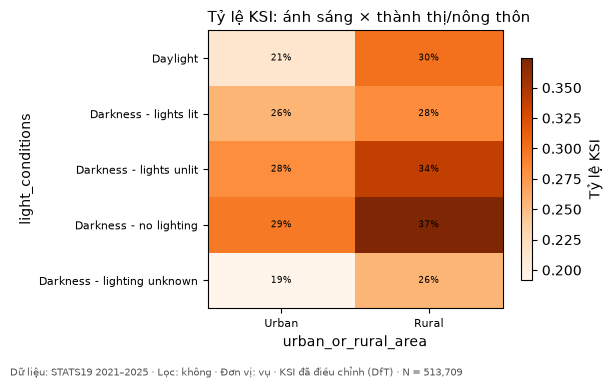

rate                 n        
urban_or_rural_area             Urban     Rural   Urban   Rural
light_conditions                                               
Daylight                     0.213932  0.300454  245304  122845
Darkness - lights lit        0.255627  0.282901   88811   17013
Darkness - lights unlit      0.281664  0.339097    2446    1260
Darkness - no lighting       0.294541  0.374368    2551   24884
Darkness - lighting unknown  0.191461  0.255345    6189    2406

In [20]:
p, n = rate_pivot(col, "light_conditions", "urban_or_rural_area")
plots.heatmap(p, "Tỷ lệ KSI: ánh sáng × thành thị/nông thôn",
              plots.data_note(int(n.sum().sum())), path=FIG / "05_light_x_urban.png")
plt.show()
pd.concat({"rate": p, "n": n}, axis=1)

Hình 5.4: ở thành thị, trời tối không có đèn đường có tỷ lệ 29,5%, so với ban ngày 21,4%; ở nông thôn là 37,4% so với 30,0%. Mức chênh lệch do bóng tối gần như tương đương ở hai khu vực (khoảng 8 điểm phần trăm), nên chưa thấy dấu hiệu tương tác rõ giữa ánh sáng và khu vực.

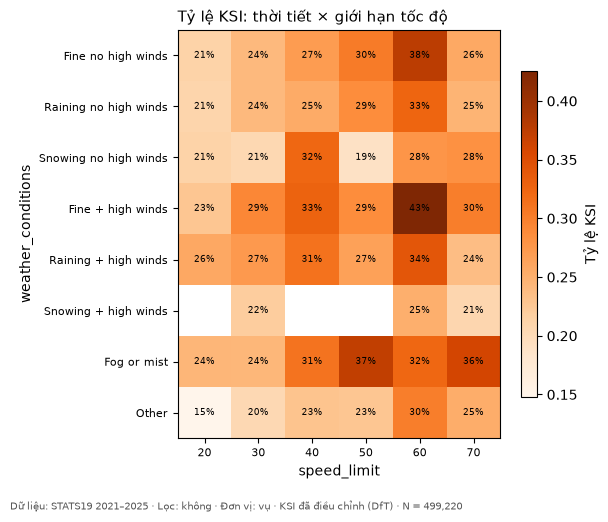

In [21]:
p, n = rate_pivot(col, "weather_conditions", "speed_limit")
plots.heatmap(p, "Tỷ lệ KSI: thời tiết × giới hạn tốc độ",
              plots.data_note(int(n.sum().sum())), path=FIG / "05_weather_x_speed.png")
plt.show()

Hình 5.5: ô trống là tổ hợp có quá ít vụ. Ở đường 20–30 mph, trời mưa và trời đẹp gần như không khác biệt (đường 20 mph: cả hai khoảng 21%; đường 30 mph: cả hai 24,0%). Ở đường 60 mph, trời mưa lại có tỷ lệ thấp hơn trời đẹp (32,6% so với 37,6%). Đây có thể là dấu hiệu tương tác giữa thời tiết và tốc độ: trên đường tốc độ cao, người lái có thể giảm tốc nhiều hơn khi trời mưa. Giả thuyết này cần được kiểm định bằng mô hình.

## 6. Thời gian

Thời điểm xảy ra tai nạn không phải yếu tố trực tiếp trong RQ1 và RQ2, nhưng phản ánh nhiều yếu tố khác (lưu lượng, tốc độ, ánh sáng, mức độ tỉnh táo của người lái), nên được dùng làm biến kiểm soát trong mô hình và là nội dung của trang Thời gian trên web.

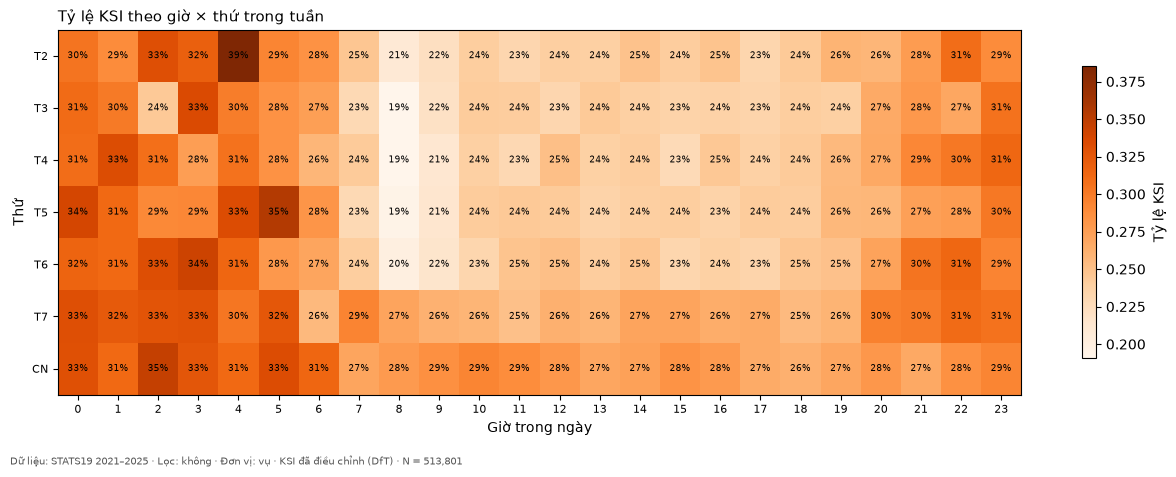

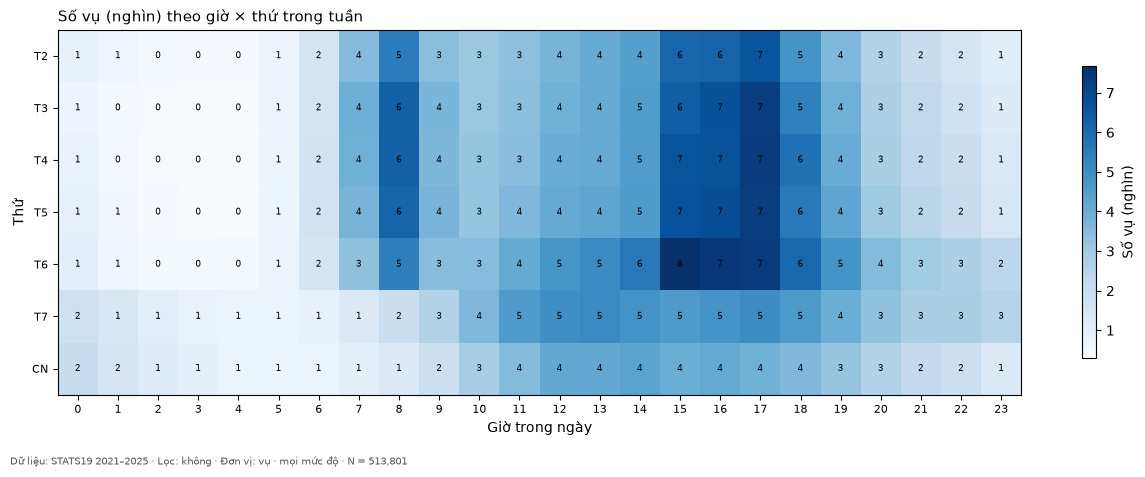

In [22]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
vn = dict(zip(order, ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]))
col["weekday"] = pd.Categorical(col["day_of_week"].astype(str).map(vn), categories=list(vn.values()))
p, n = rate_pivot(col, "weekday", "hour")
p.index.name, p.columns.name = "Thứ", "Giờ trong ngày"
plots.heatmap(p, "Tỷ lệ KSI theo giờ × thứ trong tuần", plots.data_note(int(n.sum().sum())),
              fmt="{:.0%}", path=FIG / "06_hour_x_weekday_rate.png")
plt.show()
n.index.name, n.columns.name = "Thứ", "Giờ trong ngày"
plots.heatmap(n / 1000, "Số vụ (nghìn) theo giờ × thứ trong tuần", plots.data_note(int(n.sum().sum()), severity="mọi mức độ"),
              fmt="{:.0f}", cbar_label="Số vụ (nghìn)", cmap="Blues", path=FIG / "06_hour_x_weekday_count.png")
plt.show()

Hình 6.1: mỗi ô là tỷ lệ KSI theo giờ trong ngày (cột) và thứ trong tuần (hàng; T2 là thứ Hai, CN là Chủ nhật); màu càng đậm, tỷ lệ càng cao. Ban đêm, từ khoảng 21 giờ đến 5 giờ sáng, đậm hơn rõ rệt ở mọi ngày. Khung 7–9 giờ sáng các ngày trong tuần nhạt nhất (21,3%). Thứ Bảy và Chủ nhật cao hơn ngày thường ở hầu hết các giờ (27,8% so với 24,4%).

Hình 6.2: số vụ tập trung vào giờ cao điểm sáng và chiều các ngày trong tuần, nhiều nhất lúc 17 giờ (44.792 vụ trong 5 năm). So sánh hai hình cho thấy giờ có nhiều vụ nhất không phải giờ có tỷ lệ nghiêm trọng cao nhất: ban đêm ít vụ hơn, nhưng mỗi vụ thường nặng hơn.

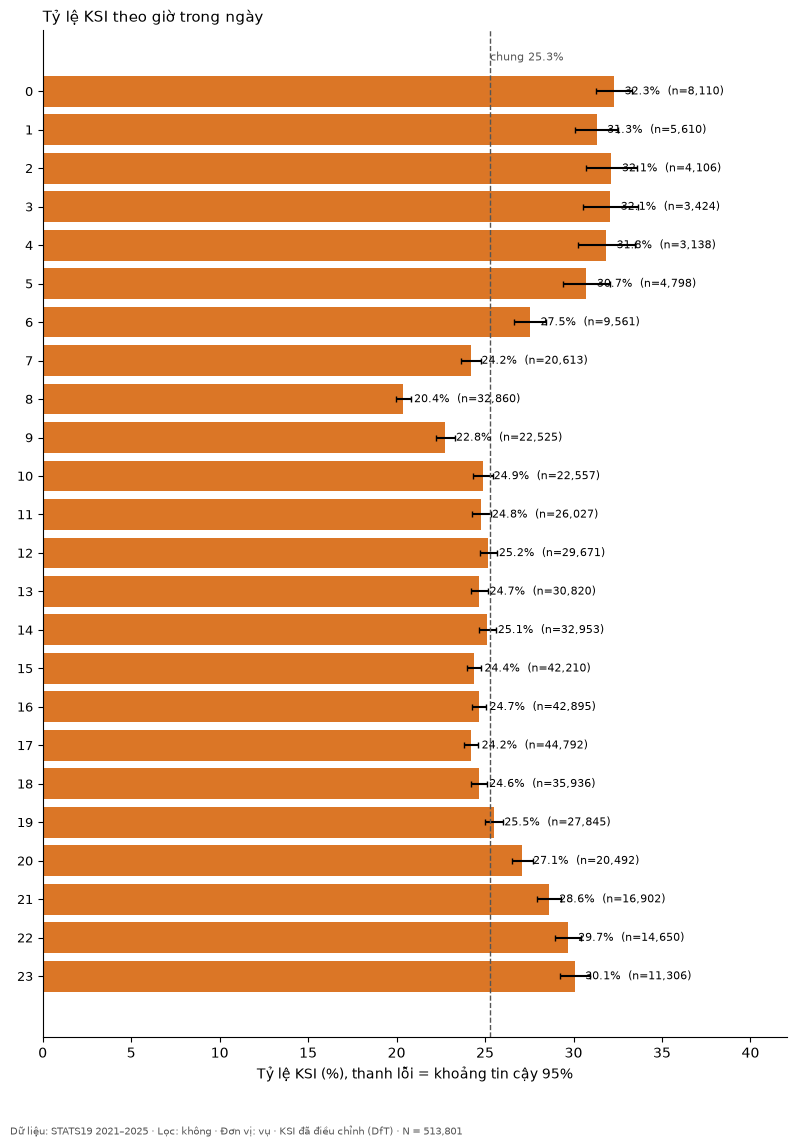

,n,ksi,rate,ci_low,ci_high,rate_raw,small_n
hour,,,,,,,
0,"8,110","2,619",32.3%,31.3%,33.3%,30.9%,False
1,"5,610","1,756",31.3%,30.1%,32.5%,30.1%,False
2,"4,106","1,320",32.1%,30.7%,33.6%,30.9%,False
3,"3,424","1,098",32.1%,30.5%,33.7%,30.8%,False
4,"3,138",999,31.8%,30.2%,33.5%,30.7%,False
5,"4,798","1,474",30.7%,29.4%,32.0%,29.5%,False
6,"9,561","2,633",27.5%,26.6%,28.4%,26.4%,False
7,"20,613","4,988",24.2%,23.6%,24.8%,23.3%,False
8,"32,860","6,700",20.4%,20.0%,20.8%,19.4%,False


In [23]:
show("hour", "Tỷ lệ KSI theo giờ trong ngày", "06_hour")

Hình 6.3: tỷ lệ thấp nhất lúc 8 giờ sáng (20,4%), là giờ cao điểm đi làm với tốc độ di chuyển chậm, và cao nhất lúc 0 giờ (32,3%).

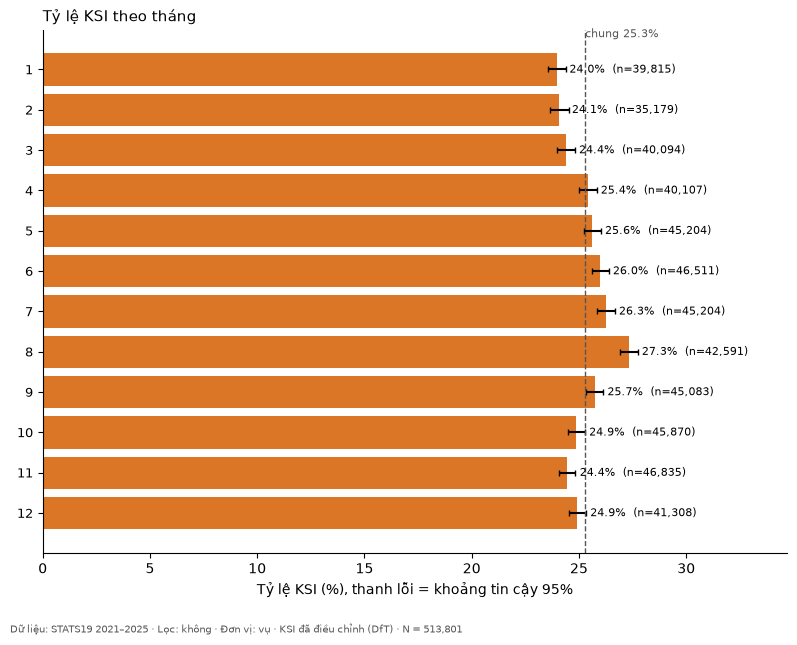

,n,ksi,rate,ci_low,ci_high,rate_raw,small_n
month,,,,,,,
1,"39,815","9,538",24.0%,23.5%,24.4%,22.8%,False
2,"35,179","8,469",24.1%,23.6%,24.5%,22.9%,False
3,"40,094","9,784",24.4%,24.0%,24.8%,23.3%,False
4,"40,107","10,195",25.4%,25.0%,25.8%,24.3%,False
5,"45,204","11,580",25.6%,25.2%,26.0%,24.5%,False
6,"46,511","12,085",26.0%,25.6%,26.4%,24.9%,False
7,"45,204","11,873",26.3%,25.9%,26.7%,25.2%,False
8,"42,591","11,642",27.3%,26.9%,27.8%,26.2%,False
9,"45,083","11,600",25.7%,25.3%,26.1%,24.7%,False


In [24]:
show("month", "Tỷ lệ KSI theo tháng", "06_month")

Hình 6.4: các tháng mùa hè có tỷ lệ cao hơn mùa đông: tháng 8 cao nhất (27,3%), tháng 1 và 2 thấp nhất (khoảng 24,0%). Một cách giải thích có thể là vào mùa hè có nhiều xe máy, xe đạp và chuyến đi đường dài hơn; giả thuyết này chưa được kiểm chứng.

## 7. Phương tiện và con người (RQ3)

Câu hỏi: ngoài đường xá và môi trường, các đặc điểm về phương tiện và con người liên quan thế nào đến mức độ nghiêm trọng? Mục này chỉ mô tả từng yếu tố; mức độ quan trọng khi xét đồng thời sẽ được đánh giá bằng mô hình XGBoost và SHAP.

Mỗi biến "có …" là đặc điểm của vụ, được gộp từ bảng phương tiện và bảng nạn nhân. Ví dụ "có xe máy" nghĩa là trong vụ có ít nhất một xe máy.

Lưu ý: các biến về nạn nhân (có người đi bộ, có người cao tuổi bị thương…) chỉ được ghi nhận khi người đó đã bị thương, nên có nguy cơ rò rỉ thông tin về kết quả. Việc có đưa các biến này vào mô hình hay không sẽ được cân nhắc khi đặc tả mô hình.

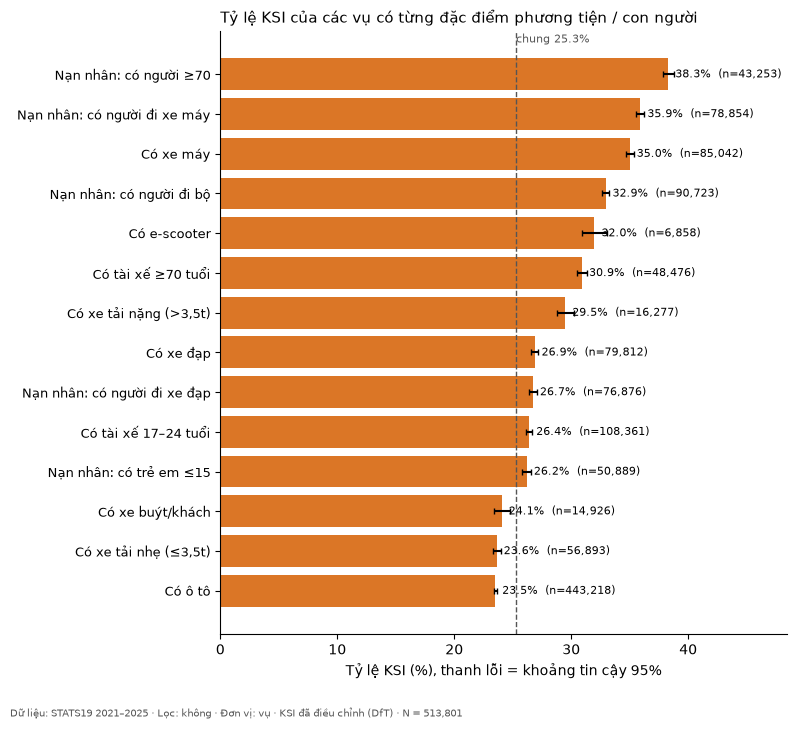

,n,ksi,rate,ci_low,ci_high,rate_raw,small_n
Nạn nhân: có người ≥70,"43,253","16,566",38.3%,37.8%,38.8%,36.6%,False
Nạn nhân: có người đi xe máy,"78,854","28,319",35.9%,35.6%,36.2%,34.7%,False
Có xe máy,"85,042","29,768",35.0%,34.7%,35.3%,33.8%,False
Nạn nhân: có người đi bộ,"90,723","29,877",32.9%,32.6%,33.2%,31.8%,False
Có e-scooter,"6,858","2,194",32.0%,30.9%,33.1%,30.8%,False
Có tài xế ≥70 tuổi,"48,476","14,991",30.9%,30.5%,31.3%,29.4%,False
"Có xe tải nặng (>3,5t)","16,277","4,800",29.5%,28.8%,30.2%,28.5%,False
Có xe đạp,"79,812","21,443",26.9%,26.6%,27.2%,25.6%,False
Nạn nhân: có người đi xe đạp,"76,876","20,548",26.7%,26.4%,27.0%,25.5%,False
Có tài xế 17–24 tuổi,"108,361","28,617",26.4%,26.1%,26.7%,25.3%,False


In [25]:
flags = {
    "has_pedal_cycle": "Có xe đạp", "has_motorcycle": "Có xe máy", "has_car": "Có ô tô",
    "has_bus_coach": "Có xe buýt/khách", "has_light_goods": "Có xe tải nhẹ (≤3,5t)",
    "has_heavy_goods": "Có xe tải nặng (>3,5t)", "has_escooter": "Có e-scooter",
    "has_young_driver": "Có tài xế 17–24 tuổi", "has_older_driver": "Có tài xế ≥70 tuổi",
    "has_pedestrian_casualty": "Nạn nhân: có người đi bộ", "has_cyclist_casualty": "Nạn nhân: có người đi xe đạp",
    "has_motorcyclist_casualty": "Nạn nhân: có người đi xe máy", "has_child_casualty": "Nạn nhân: có trẻ em ≤15",
    "has_older_casualty": "Nạn nhân: có người ≥70",
}
rows = []
for c, name in flags.items():
    t = ksi_rate_table(col, c)
    if True in t.index:
        rows.append(t.loc[True].rename(name))
ft = pd.DataFrame(rows).sort_values("rate", ascending=False)
ft["small_n"] = ft["small_n"].astype(bool)
ft.to_csv(TAB / "07_flags.csv")
plots.rate_bars(ft, "Tỷ lệ KSI của các vụ có từng đặc điểm phương tiện / con người",
                plots.data_note(len(col)), overall=OVERALL, path=FIG / "07_flags.png")
plt.show()
ft.style.format({"rate": "{:.1%}", "ci_low": "{:.1%}", "ci_high": "{:.1%}", "rate_raw": "{:.1%}",
                 "ksi": "{:,.0f}", "n": "{:,.0f}"})

Hình 7.1: mỗi thanh là tỷ lệ KSI của các vụ có đặc điểm tương ứng. Một vụ có thể có nhiều đặc điểm cùng lúc (ví dụ vừa có ô tô vừa có xe máy), nên các thanh không cộng lại được. Các vụ có nạn nhân từ 70 tuổi trở lên (38,3%), có người đi xe máy bị thương (35,9%) và có xe máy (35,0%) có tỷ lệ cao nhất. Các vụ có ô tô, xe tải nhẹ hoặc xe buýt có tỷ lệ gần hoặc thấp hơn mức chung, một phần vì người ngồi trong các loại xe này được bảo vệ tốt hơn.

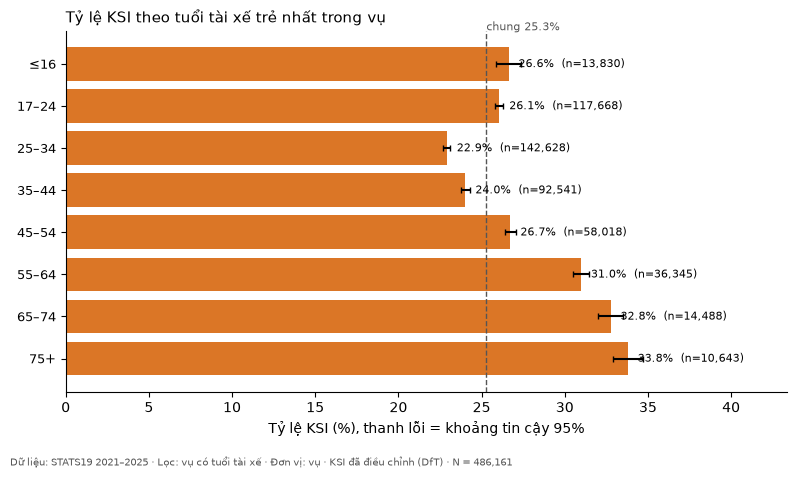

,n,ksi,rate,ci_low,ci_high,rate_raw,small_n
min_driver_age_band,,,,,,,
≤16,"13,830","3,682",26.6%,25.9%,27.4%,25.1%,False
17–24,"117,668","30,670",26.1%,25.8%,26.3%,24.9%,False
25–34,"142,628","32,678",22.9%,22.7%,23.1%,22.0%,False
35–44,"92,541","22,236",24.0%,23.8%,24.3%,23.1%,False
45–54,"58,018","15,511",26.7%,26.4%,27.1%,25.6%,False
55–64,"36,345","11,257",31.0%,30.5%,31.5%,29.7%,False
65–74,"14,488","4,745",32.8%,32.0%,33.5%,31.2%,False
75+,"10,643","3,595",33.8%,32.9%,34.7%,32.1%,False


In [26]:
bins = [0, 16, 24, 34, 44, 54, 64, 74, 120]
labels = ["≤16", "17–24", "25–34", "35–44", "45–54", "55–64", "65–74", "75+"]
col["min_driver_age_band"] = pd.cut(col["min_driver_age"], bins=bins, labels=labels)
show("min_driver_age_band", "Tỷ lệ KSI theo tuổi tài xế trẻ nhất trong vụ", "07_min_driver_age",
     filters="vụ có tuổi tài xế")

Hình 7.2: nhóm tuổi được tính theo người điều khiển phương tiện trẻ nhất trong vụ. Tỷ lệ thấp nhất ở nhóm 25–34 tuổi (22,9%), sau đó tăng đều theo tuổi, đến 33,8% ở nhóm từ 75 tuổi. Nhóm 17–24 tuổi (26,1%) cao hơn nhóm 25–34 tuổi. Nhóm từ 16 tuổi trở xuống chủ yếu là trẻ em đi xe đạp (69%) và e-scooter (10%), vì trong STATS19 người điều khiển xe đạp cũng được ghi nhận là người lái.

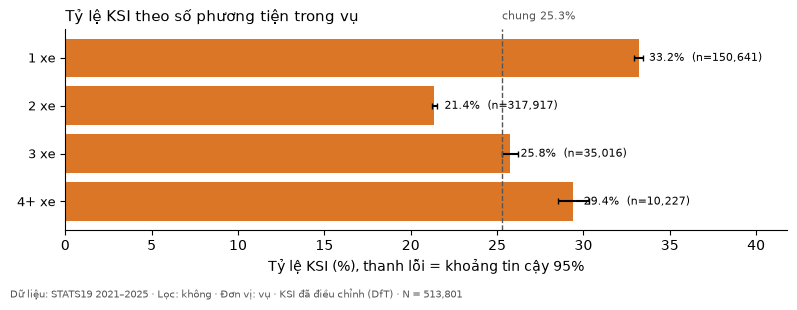

,n,ksi,rate,ci_low,ci_high,rate_raw,small_n
vehicles_band,,,,,,,
1 xe,"150,641","50,001",33.2%,33.0%,33.4%,31.9%,False
2 xe,"317,917","67,889",21.4%,21.2%,21.5%,20.4%,False
3 xe,"35,016","9,020",25.8%,25.3%,26.2%,24.7%,False
4+ xe,"10,227","3,009",29.4%,28.5%,30.3%,28.4%,False


In [27]:
col["vehicles_band"] = pd.cut(col["number_of_vehicles"], [0, 1, 2, 3, 100], labels=["1 xe", "2 xe", "3 xe", "4+ xe"])
show("vehicles_band", "Tỷ lệ KSI theo số phương tiện trong vụ", "07_n_vehicles")

Hình 7.3: vụ chỉ có một phương tiện có tỷ lệ cao nhất (33,2%). Nhóm này gồm các vụ xe lao khỏi đường, đâm vào vật cố định hoặc đâm vào người đi bộ (người đi bộ không được tính là phương tiện). Vụ có hai phương tiện có tỷ lệ thấp nhất (21,4%).

## 8. Phân tích ở mức người bị thương

Trong mục này, mỗi dòng là một người bị thương (652.821 người), và KSI là mức độ thương tích của chính người đó (đã điều chỉnh). Tỷ lệ chung ở mức người là 21,9%, thấp hơn mức vụ (25,3%) vì một vụ KSI có thể có cả người bị thương nhẹ.

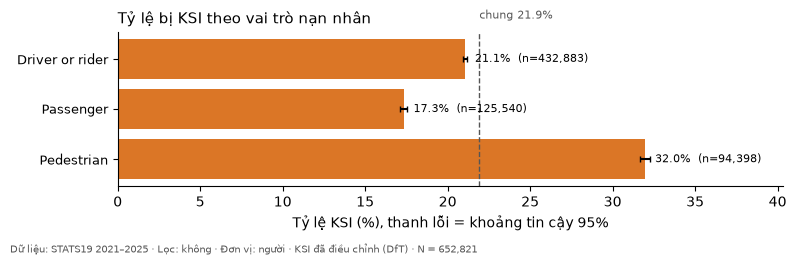

,n,ksi,rate,ci_low,ci_high,rate_raw,small_n
casualty_class,,,,,,,
Driver or rider,"432,883","91,148",21.1%,20.9%,21.2%,20.1%,False
Passenger,"125,540","21,760",17.3%,17.1%,17.5%,16.6%,False
Pedestrian,"94,398","30,182",32.0%,31.7%,32.3%,30.8%,False


In [28]:
show("casualty_class", "Tỷ lệ bị KSI theo vai trò nạn nhân", "08_casualty_class", df=cas, unit="người")

Hình 8.1: Driver or rider là người điều khiển phương tiện; Passenger là hành khách; Pedestrian là người đi bộ. Người đi bộ có tỷ lệ bị thương nặng hoặc tử vong cao nhất (32,0%), cao hơn người điều khiển (21,1%) và hành khách (17,3%).

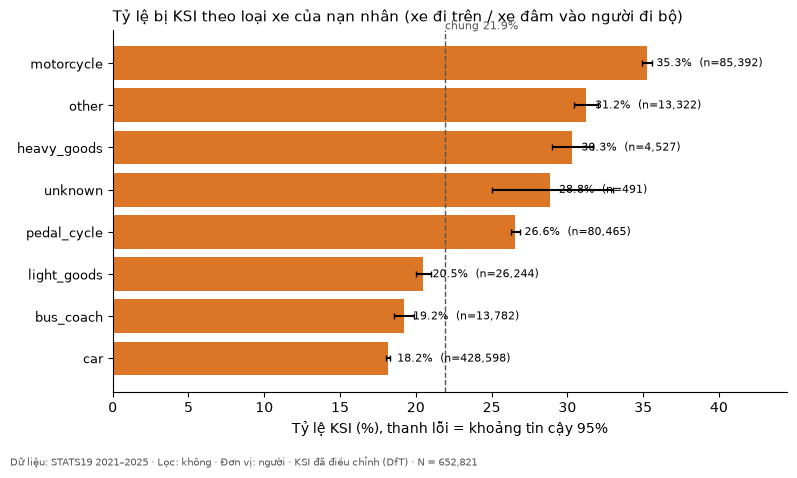

,n,ksi,rate,ci_low,ci_high,rate_raw,small_n
casualty_vehicle_group,,,,,,,
motorcycle,"85,392","30,121",35.3%,35.0%,35.6%,34.1%,False
other,"13,322","4,160",31.2%,30.4%,32.0%,29.9%,False
heavy_goods,"4,527","1,373",30.3%,29.0%,31.7%,29.0%,False
unknown,491,142,28.8%,25.0%,33.0%,28.3%,False
pedal_cycle,"80,465","21,381",26.6%,26.3%,26.9%,25.3%,False
light_goods,"26,244","5,381",20.5%,20.0%,21.0%,19.6%,False
bus_coach,"13,782","2,648",19.2%,18.6%,19.9%,18.7%,False
car,"428,598","77,886",18.2%,18.1%,18.3%,17.4%,False


In [29]:
show("casualty_vehicle_group", "Tỷ lệ bị KSI theo loại xe của nạn nhân (xe đi trên / xe đâm vào người đi bộ)", "08_vehicle_group", df=cas, unit="người", sort=True)

Hình 8.2: nhóm xe được xếp theo cách phân loại trong bảng RAS0101 của DfT: motorcycle là xe máy; pedal_cycle là xe đạp; car là ô tô (gồm taxi và minibus); light_goods là xe tải đến 3,5 tấn; heavy_goods là xe tải trên 3,5 tấn; bus_coach là xe buýt và xe khách; other gồm e-scooter, xe lăn điện, xe nông nghiệp, ngựa, tàu điện; unknown là không rõ. Với người đi bộ, đây là loại xe đã đâm vào họ. Người đi trên xe máy có tỷ lệ cao nhất (35,3%), gần gấp đôi người đi trên ô tô (18,2%).

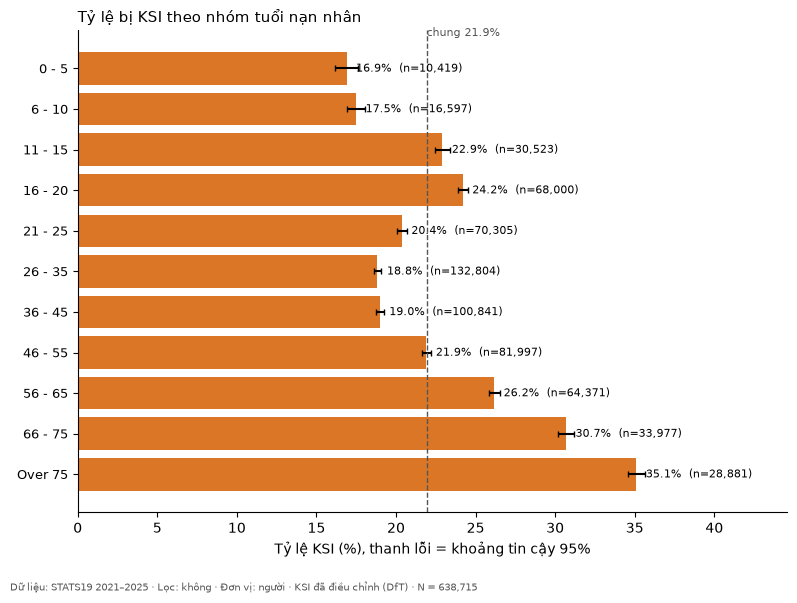

,n,ksi,rate,ci_low,ci_high,rate_raw,small_n
age_band_of_casualty,,,,,,,
0 - 5,"10,419","1,760",16.9%,16.2%,17.6%,16.0%,False
6 - 10,"16,597","2,904",17.5%,16.9%,18.1%,16.6%,False
11 - 15,"30,523","6,994",22.9%,22.4%,23.4%,21.8%,False
16 - 20,"68,000","16,453",24.2%,23.9%,24.5%,23.1%,False
21 - 25,"70,305","14,319",20.4%,20.1%,20.7%,19.5%,False
26 - 35,"132,804","25,014",18.8%,18.6%,19.0%,18.1%,False
36 - 45,"100,841","19,141",19.0%,18.7%,19.2%,18.2%,False
46 - 55,"81,997","17,964",21.9%,21.6%,22.2%,21.0%,False
56 - 65,"64,371","16,844",26.2%,25.8%,26.5%,25.1%,False


In [30]:
show("age_band_of_casualty", "Tỷ lệ bị KSI theo nhóm tuổi nạn nhân", "08_age_band", df=cas, unit="người")

Hình 8.3: tỷ lệ thấp ở trẻ nhỏ (0–5 tuổi: 16,9%) và nhóm 26–45 tuổi (khoảng 19%), có một đỉnh nhỏ ở nhóm 16–20 tuổi (24,2%), sau đó tăng mạnh từ 56 tuổi và cao nhất ở nhóm trên 75 tuổi (35,1%). Người cao tuổi dễ bị thương nặng hơn khi gặp cùng một tai nạn.

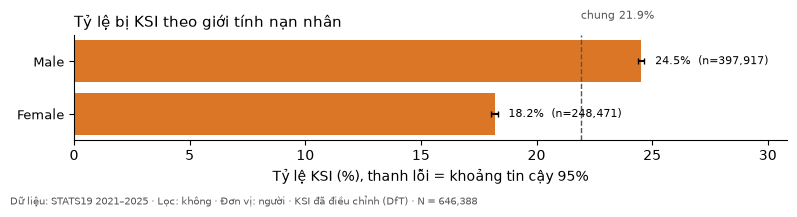

,n,ksi,rate,ci_low,ci_high,rate_raw,small_n
sex_of_casualty,,,,,,,
Male,"397,917","97,616",24.5%,24.4%,24.7%,23.5%,False
Female,"248,471","45,186",18.2%,18.0%,18.3%,17.4%,False


In [31]:
show("sex_of_casualty", "Tỷ lệ bị KSI theo giới tính nạn nhân", "08_sex", df=cas, unit="người")

Hình 8.4: Male là nam, Female là nữ. Nam giới có tỷ lệ bị thương nặng hoặc tử vong cao hơn nữ giới (24,5% so với 18,2%), một phần có thể vì tỷ lệ nam giới đi xe máy cao hơn; điều này cần kiểm soát trong mô hình.

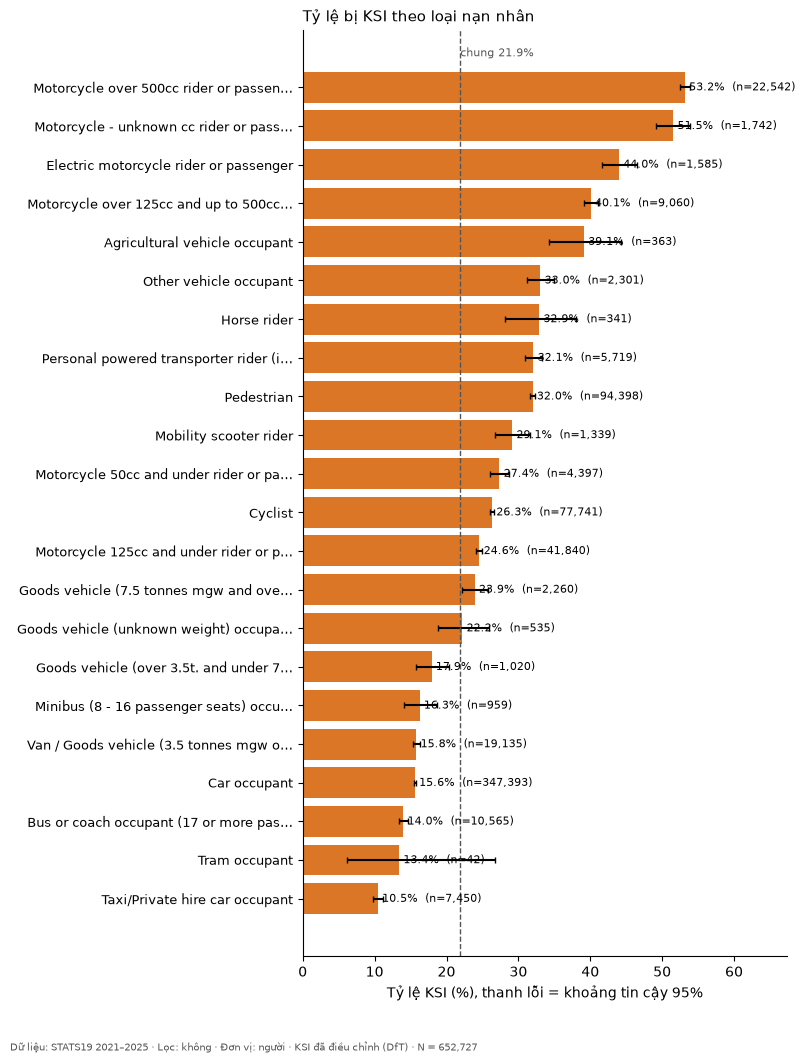

,n,ksi,rate,ci_low,ci_high,rate_raw,small_n
casualty_type,,,,,,,
Motorcycle over 500cc rider or passenger,"22,542","11,983",53.2%,52.5%,53.8%,51.7%,False
Motorcycle - unknown cc rider or passenger,"1,742",898,51.5%,49.2%,53.9%,50.7%,False
Electric motorcycle rider or passenger,"1,585",697,44.0%,41.6%,46.4%,43.0%,False
Motorcycle over 125cc and up to 500cc rider or passenger,"9,060","3,630",40.1%,39.1%,41.1%,38.1%,False
Agricultural vehicle occupant,363,142,39.1%,34.2%,44.2%,36.1%,False
Other vehicle occupant,"2,301",760,33.0%,31.2%,35.0%,31.7%,False
Horse rider,341,112,32.9%,28.1%,38.0%,31.7%,False
Personal powered transporter rider (incl. e-scooter),"5,719","1,835",32.1%,30.9%,33.3%,31.0%,False
Pedestrian,"94,398","30,182",32.0%,31.7%,32.3%,30.8%,False


In [32]:
show("casualty_type", "Tỷ lệ bị KSI theo loại nạn nhân", "08_casualty_type", df=cas, unit="người", sort=True)

Hình 8.5: chi tiết theo loại nạn nhân. Người đi xe máy trên 500cc có tỷ lệ cao nhất (53,2%, tức hơn một nửa số người bị thương thuộc nhóm này bị thương nặng hoặc tử vong). Người trong ô tô (15,6%), xe buýt (14,0%) và taxi (10,5%) có tỷ lệ thấp nhất.

## 9. Mô tả ban đầu cho RQ4: Wales và England

Câu hỏi: việc Wales hạ giới hạn tốc độ mặc định từ 30 xuống 20 mph từ ngày 17/9/2023 có làm thay đổi mức độ nghiêm trọng của tai nạn so với England không?

Mục này chỉ mang tính mô tả, chưa phải phân tích difference-in-differences. Mẫu gồm các vụ ở khu vực thành thị, trên đường có giới hạn 20 hoặc 30 mph, tại England và Wales. Đường đứt nét đánh dấu ngày 17/9/2023.

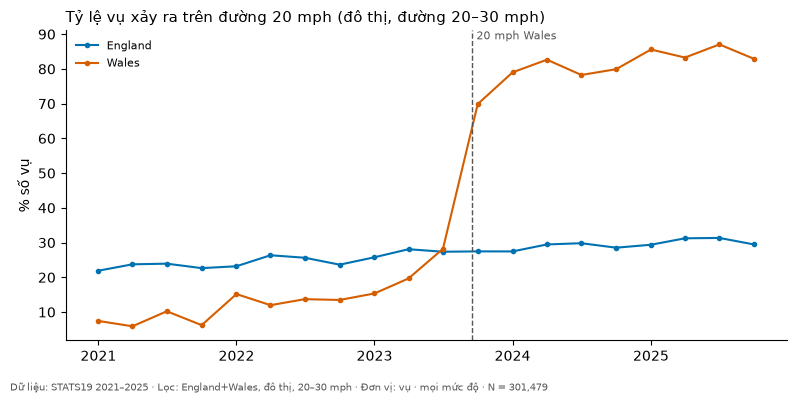

quarter,2021-01-01,2021-04-01,2021-07-01,2021-10-01,2022-01-01,2022-04-01,2022-07-01,2022-10-01,2023-01-01,2023-04-01,2023-07-01,2023-10-01,2024-01-01,2024-04-01,2024-07-01,2024-10-01,2025-01-01,2025-04-01,2025-07-01,2025-10-01
country,,,,,,,,,,,,,,,,,,,,
England,0.219,0.237,0.239,0.226,0.232,0.264,0.256,0.236,0.258,0.281,0.274,0.275,0.275,0.295,0.298,0.285,0.294,0.312,0.313,0.295
Wales,0.074,0.059,0.102,0.062,0.152,0.12,0.137,0.135,0.154,0.197,0.282,0.699,0.79,0.827,0.783,0.799,0.856,0.833,0.871,0.829


In [33]:
did = col[col.country.isin(["England", "Wales"]) & (col.urban_or_rural_area == "Urban")
          & col.speed_limit.isin([20, 30])].copy()
did["country"] = did["country"].cat.remove_unused_categories()
share20 = did.assign(is20=did.speed_limit.eq(20)).groupby(["quarter", "country"], observed=True)["is20"].mean().unstack()
plots.lines(share20, "Tỷ lệ vụ xảy ra trên đường 20 mph (đô thị, đường 20–30 mph)",
            plots.data_note(len(did), filters="England+Wales, đô thị, 20–30 mph", severity="mọi mức độ"),
            ylabel="% số vụ", colors=plots.SERIES_COLORS, vline=(pd.Timestamp(POLICY_DATE), "20 mph Wales"),
            path=FIG / "09_share_20mph.png")
plt.show()
share20.round(3).T

Hình 9.1: trong số các vụ trên đường 20–30 mph ở thành thị, tỷ lệ vụ xảy ra trên đường 20 mph ở Wales chỉ khoảng 6–20% từ 2021 đến quý 1/2023, tăng lên 28% ngay trước thời điểm áp dụng (một số nơi triển khai sớm), rồi lên khoảng 70–87% từ quý 4/2023. Ở England, tỷ lệ này ổn định trong khoảng 22–31%. Thay đổi giới hạn tốc độ thể hiện rõ trong dữ liệu, cho thấy chính sách đã được triển khai trên thực tế.

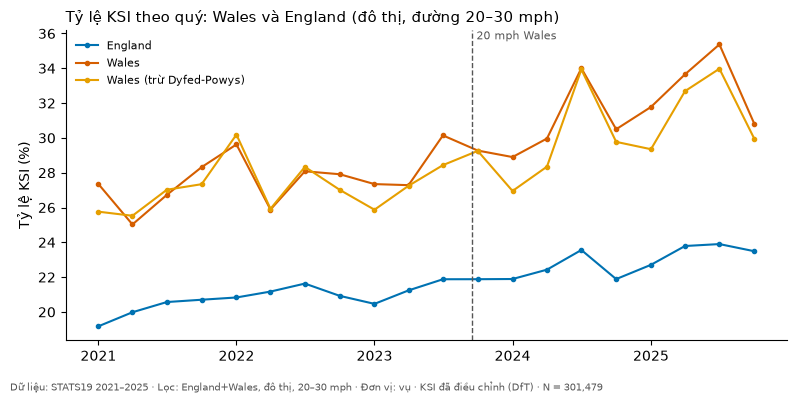

Số vụ mỗi quý, Wales: 215 – 356


In [34]:
q = did.groupby(["quarter", "country"], observed=True)["ksi_adj"].agg(["mean", "size"]).unstack()
rate = q["mean"]
dp = did[(did.country == "Wales") & (did.police_force != "Dyfed-Powys")]
rate["Wales (trừ Dyfed-Powys)"] = dp.groupby("quarter")["ksi_adj"].mean()
plots.lines(rate, "Tỷ lệ KSI theo quý: Wales và England (đô thị, đường 20–30 mph)",
            plots.data_note(len(did), filters="England+Wales, đô thị, 20–30 mph"), ylabel="Tỷ lệ KSI (%)",
            colors={**plots.SERIES_COLORS, "Wales (trừ Dyfed-Powys)": "#E69F00"},
            vline=(pd.Timestamp(POLICY_DATE), "20 mph Wales"), path=FIG / "09_ksi_wales_england.png")
plt.show()
print("Số vụ mỗi quý, Wales:", q["size"]["Wales"].min(), "–", q["size"]["Wales"].max())
pre = did.date < pd.Timestamp(POLICY_DATE)
did.assign(period=np.where(pre, "1. trước", "2. sau")).groupby(["country", "period"], observed=True)["ksi_adj"].agg(
    ["size", "mean"]).style.format({"size": "{:,}", "mean": "{:.2%}"})

Hình 9.2: đường xanh là England, đường cam đậm là Wales, đường cam nhạt là Wales không tính Dyfed-Powys (để loại ảnh hưởng của việc lực lượng này đổi cách ghi năm 2023). Trong giai đoạn trước chính sách, Wales luôn cao hơn England khoảng 5–8 điểm phần trăm; sau tháng 9/2023 khoảng cách có xu hướng rộng hơn. Hai đường của Wales gần nhau, cho thấy việc Dyfed-Powys đổi cách ghi không phải nguyên nhân chính của sự thay đổi. Mỗi quý Wales chỉ có vài trăm vụ trong mẫu, nên đường của Wales dao động mạnh.

Bảng 9.1: tỷ lệ KSI ở Wales tăng từ 27,6% lên 31,5% (+3,8 điểm phần trăm), ở England từ 20,8% lên 22,8% (+2,0 điểm phần trăm). Mức tăng chênh lệch khoảng 1,8 điểm phần trăm này chưa phải là tác động của chính sách: cần kiểm tra giả định xu hướng song song, kiểm soát các yếu tố khác và xét cả số vụ, vì nếu chính sách làm giảm các vụ nhẹ nhiều hơn các vụ nặng thì tỷ lệ KSI vẫn có thể tăng dù đường an toàn hơn (hiệu ứng thành phần).

## 10. Tổng kết

Các số liệu dưới đây được tính trên dữ liệu STATS19 2021–2025 (Great Britain), dùng KSI đã điều chỉnh, đơn vị là vụ tai nạn (N = 513.801) trừ các dòng ghi "mức người". Đây là tương quan giữa từng yếu tố với mức độ nghiêm trọng, chưa kiểm soát các yếu tố khác, và chỉ xét các vụ đã có người bị thương.

### Các kết quả chính

| # | Yếu tố | Số liệu | Nhận xét |
|---|---|---|---|
| 1 | Giới hạn tốc độ | 20 mph: 20,4%; 60 mph: 36,5%; 70 mph: 25,4% | Tỷ lệ KSI tăng dần theo giới hạn tốc độ đến 60 mph. Đường 70 mph, chủ yếu là đường cao tốc có dải phân cách và không có người đi bộ, có tỷ lệ thấp hơn. |
| 2 | Khu vực và loại đường | Nông thôn 30,9%, thành thị 22,5%; đường hai chiều không có dải phân cách 27,2%, vòng xuyến 18,1% | Vụ ở nông thôn và trên đường không có dải phân cách gắn với mức độ nghiêm trọng cao hơn. |
| 3 | Ánh sáng | Trời tối không có đèn đường 36,7%, ban ngày 24,3% | Trời tối không có chiếu sáng gắn với tỷ lệ KSI cao hơn khoảng 12 điểm phần trăm. |
| 4 | Ánh sáng theo khu vực | Thành thị: 29,5% (tối không đèn) và 21,4% (ban ngày); nông thôn: 37,4% và 30,0% | Mức chênh lệch do bóng tối gần như tương đương ở hai khu vực (khoảng 8 điểm phần trăm); cần kiểm định tương tác bằng mô hình. |
| 5 | Thời tiết và mặt đường | Mưa 25,0%, trời đẹp 25,8%; mặt đường ướt 26,5%, khô 25,4%; riêng đường 60 mph: mưa 32,6%, trời đẹp 37,6% | Nhìn chung thời tiết hầu như không gắn với khác biệt về mức độ nghiêm trọng. Trên đường tốc độ cao, trời mưa lại gắn với tỷ lệ thấp hơn, có thể vì người lái giảm tốc khi thời tiết xấu (dấu hiệu tương tác, cần kiểm định). |
| 6 | Thời gian | 0–5 giờ sáng: khoảng 31–32% (5 giờ: 30,7%); 8 giờ sáng: 20,4%; cuối tuần cao hơn ngày thường | Vụ xảy ra ban đêm và vào cuối tuần gắn với mức độ nghiêm trọng cao hơn; giờ cao điểm sáng các ngày trong tuần có tỷ lệ thấp nhất. |
| 7 | Phương tiện và người lái | Vụ có xe máy 35,0%; vụ một xe 33,2%, vụ hai xe 21,4%; tài xế trẻ nhất từ 75 tuổi trở lên 33,8% | Sự có mặt của xe máy, vụ chỉ có một phương tiện và người lái cao tuổi gắn với tỷ lệ KSI cao. |
| 8 | Mức người | Người đi xe máy trên 500cc 53,2%; người đi bộ 32,0%; người trong ô tô 15,6%; nam 24,5%, nữ 18,2%; trên 75 tuổi 35,1% | Người đi xe máy phân khối lớn và người đi bộ có tỷ lệ bị thương nặng cao nhất; người cao tuổi bị thương nặng hơn khi gặp tai nạn. |
| 9 | Triển khai chính sách 20 mph | Tỷ lệ vụ trên đường 20 mph (thành thị, đường 20–30 mph) ở Wales: khoảng 6–20% từ 2021 đến quý 1/2023, 28% ngay trước khi áp dụng (một số nơi triển khai sớm), sau đó khoảng 70–87%; England ổn định ở mức 22–31% | Thay đổi giới hạn tốc độ thể hiện rõ trong dữ liệu, cho thấy chính sách đã được triển khai trên thực tế. |
| 10 | Tỷ lệ KSI trước và sau chính sách | Wales: 27,6% lên 31,5% (+3,8 điểm phần trăm); England: 20,8% lên 22,8% (+2,0 điểm phần trăm) | Đây mới là so sánh mô tả, chưa phải kết quả difference-in-differences. Mẫu Wales nhỏ (khoảng 5.600 vụ) và dao động lớn theo quý. Số vụ ở Wales cũng giảm, nên tỷ lệ KSI có thể tăng nếu các vụ nhẹ giảm nhiều hơn các vụ nặng (hiệu ứng thành phần). Vì vậy phân tích chính sách cần xét cả số vụ, không chỉ tỷ lệ. |

### Chất lượng dữ liệu

- `junction_control`: khi vụ không xảy ra ở giao lộ, cảnh sát để trống biến này. Các giá trị trống đó mang nghĩa "không áp dụng" chứ không phải thiếu dữ liệu, nên đã được gán nhãn "Not at junction or within 20 metres" (nhãn có sẵn trong Data Guide) ở bước làm sạch. Tỷ lệ thiếu thực sự còn 2,9%.
- `special_conditions_at_site`: biến này được thay thế trong đặc tả dữ liệu năm 2024 (tỷ lệ thiếu tăng từ 0,3% năm 2021 lên 87% năm 2025), nên không được sử dụng; thông tin tương ứng nằm trong `carriageway_hazards`.
- `enhanced_severity_collision` (thiếu 40%) và `second_road_number` (thiếu 35%) không được sử dụng.
- Tuổi tài xế thiếu ở 5,4% số vụ; mô hình sẽ dùng thêm một nhóm "không rõ".

### Biến dự kiến cho mô hình

| Nhóm | Biến | Ghi chú |
|---|---|---|
| Đường (RQ1) | `speed_limit`, `road_type`, `urban_or_rural_area`, `first_road_class`, `junction_detail`, `junction_control` | Kiểm tra đa cộng tuyến (VIF) giữa giới hạn tốc độ, loại đường và khu vực |
| Môi trường (RQ2) | `light_conditions`, `weather_conditions`, `road_surface_conditions`, `carriageway_hazards` | Tương tác dự kiến: ánh sáng × khu vực, thời tiết × giới hạn tốc độ |
| Thời gian | nhóm giờ, `day_of_week`, mùa | |
| Phương tiện và người lái (RQ3) | các biến `has_<nhóm xe>`, `has_escooter`, nhóm tuổi tài xế trẻ nhất và lớn nhất, `number_of_vehicles` | |
| Biến kiểm soát | `collision_year`, `police_force` | Xu hướng theo năm và khác biệt cách ghi nhận giữa các lực lượng cảnh sát |
| Cần cân nhắc | `has_pedestrian_casualty`, `has_older_casualty` và các biến khác về nạn nhân | Chỉ được ghi nhận khi đã có người bị thương, có nguy cơ rò rỉ thông tin về kết quả |
| Không sử dụng | `number_of_casualties`, `enhanced_severity_collision`, `did_police_officer_attend_scene_of_accident`, `special_conditions_at_site`, các biến `*_historic`, `journey_purpose_of_driver`, `driver_distance_banding`, LSOA | Là hệ quả của mức độ nghiêm trọng (ví dụ cảnh sát thường có mặt tại hiện trường khi vụ nặng), hoặc thiếu quá nhiều dữ liệu |